In [ ]:
import cdsapi

dataset = "reanalysis-era5-pressure-levels"
request = {
    "product_type": ["reanalysis"],
    "variable": ["temperature"],
    "year": [
        "1950", "1951", "1952",
        "1953", "1954", "1955",
        "1956", "1957", "1958",
        "1959", "1960", "1961",
        "1962", "1963", "1964",
        "1965", "1966", "1967",
        "1968", "1969", "1970",
        "1971", "1972", "1973",
        "1974", "1975", "1976",
        "1977", "1978", "1979",
        "1980", "1981", "1982",
        "1983", "1984", "1985",
        "1986", "1987"
    ],
    "month": [
        "01", "02", "10",
        "11", "12"
    ],
    "day": [
        "01", "02", "03",
        "04", "05", "06",
        "07", "08", "09",
        "10", "11", "12",
        "13", "14", "15",
        "16", "17", "18",
        "19", "20", "21",
        "22", "23", "24",
        "25", "26", "27",
        "28", "29", "30",
        "31"
    ],
    "time": [
        "00:00", "06:00", "12:00",
        "18:00"
    ],
    "pressure_level": ["100"],
    "grid": "1.0/1.0",
    "data_format": "grib",
    "download_format": "unarchived",
    "area": [90, -180, 65, 180]
}

client = cdsapi.Client()
client.retrieve(dataset, request).download()


2026-07-13 18:19:51,105 INFO Request ID is c8f941ff-86ae-4633-a2fa-57fcb3008861
2026-07-13 18:19:51,192 INFO status has been updated to accepted


In [ ]:
import cdsapi

dataset = "reanalysis-era5-pressure-levels"
request = {
    "product_type": ["reanalysis"],
    "variable": ["temperature"],
    "year": [
        "1988", "1989", "1990",
        "1991", "1992", "1993",
        "1994", "1995", "1996",
        "1997", "1998", "1999",
        "2000", "2001", "2002",
        "2003", "2004", "2005",
        "2006", "2007", "2008",
        "2009", "2010", "2011",
        "2012", "2013", "2014",
        "2015", "2016", "2017",
        "2018", "2019", "2020",
        "2021", "2022", "2023",
        "2024", "2025"
    ],
    "month": [
        "01", "02", "10",
        "11", "12"
    ],
    "day": [
        "01", "02", "03",
        "04", "05", "06",
        "07", "08", "09",
        "10", "11", "12",
        "13", "14", "15",
        "16", "17", "18",
        "19", "20", "21",
        "22", "23", "24",
        "25", "26", "27",
        "28", "29", "30",
        "31"
    ],
    "time": [
        "00:00", "06:00", "12:00",
        "18:00"
    ],
    "pressure_level": ["100"],
    "grid": "1.0/1.0",
    "data_format": "grib",
    "download_format": "unarchived",
    "area": [90, -180, 65, 180]
}

client = cdsapi.Client()
client.retrieve(dataset, request).download()


2026-07-13 18:21:11,899 INFO Request ID is 032feebe-2349-44a1-8886-5643e4d1278f
2026-07-13 18:21:11,964 INFO status has been updated to accepted


In [1]:
import xarray as xr
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from datetime import datetime, date

In [2]:
ds = xr.load_dataset("t100_50_87.grib", engine="cfgrib")
var_daily1 = ds.t.groupby(ds.t.time.dt.date).mean()

In [3]:
ds = xr.load_dataset("t100_88_25.grib", engine="cfgrib")
var_daily2 = ds.t.groupby(ds.t.time.dt.date).mean()

In [4]:
var_daily = xr.concat([var_daily1, var_daily2], dim='date')
var_daily = var_daily.reset_coords(['number', 'step', 'isobaricInhPa'], drop=True)

In [5]:
dates = var_daily.date.data
datetimes = np.zeros_like(dates)
for i in range(len(dates)):
    datetimes[i] = datetime.combine(dates[i], datetime.min.time())

In [6]:
var_daily.coords["time"] = ("date", datetimes)
var_daily = var_daily.swap_dims({"date": "time"})
var_daily = var_daily.reset_coords('date', drop=True)

In [7]:
var_daily = var_daily.sel(time=slice("1950-07", "2025-06"))
var_daily = var_daily.assign_coords({'month_day': 31*var_daily['time.month'] + var_daily['time.day']})
month = var_daily.time.dt.month
day = var_daily.time.dt.day
var_daily = var_daily.sel(time=~((month == 2) & (day == 29)))

In [8]:
weights = np.cos(np.deg2rad(var_daily.latitude))
weights.name = "weights"

In [9]:
var_daily_regmean = var_daily.weighted(weights).mean(dim=['longitude', 'latitude'])

In [10]:
var_seasonmean_regmean = var_daily_regmean.coarsen(time=151).construct(time=("year", "date")).mean(dim='date')

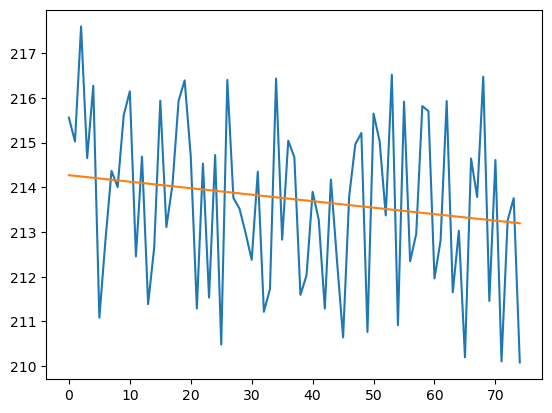

In [11]:
fit_par = np.polyfit(var_seasonmean_regmean[:60].year, var_seasonmean_regmean[:60], 1)
var_seasonmean_regmean_gws = np.polyval(fit_par, var_seasonmean_regmean.year)

plt.plot(var_seasonmean_regmean.year, var_seasonmean_regmean)
plt.plot(var_seasonmean_regmean.year, var_seasonmean_regmean_gws)

In [12]:
var_daily_regmean_detr = var_daily_regmean.coarsen(time=151).construct(time=("year", "date")) - var_seasonmean_regmean_gws[:, np.newaxis]
var_daily_regmean_detr = var_daily_regmean_detr.stack(day=("year", "date")).swap_dims({"day": "time"}).reset_coords(('day','year','date'), drop=True)

In [13]:
var_7dMean_regmean_detr = var_daily_regmean_detr.rolling(time=7, min_periods=7, center=True).mean() 
month = var_7dMean_regmean_detr.time.dt.month
day = var_7dMean_regmean_detr.time.dt.day
var_7dMean_regmean_detr = var_7dMean_regmean_detr.sel(time=~( ((month==10)&(day<4)) | ((month==2)&(day>25)) ))

var_7dMean_regmean_detr_train = var_7dMean_regmean_detr.sel(time=slice("1950-07", "2010-06"))

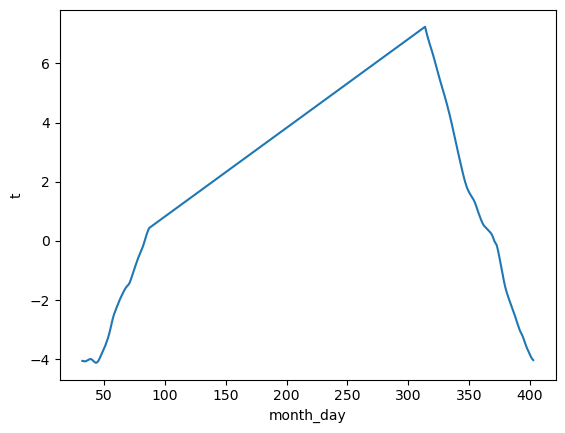

In [14]:
var_7dMean_regmean_detr_anom = var_7dMean_regmean_detr.groupby('month_day') - var_7dMean_regmean_detr_train.groupby('month_day').mean()
var_7dMean_regmean_detr_train.groupby('month_day').mean().plot()

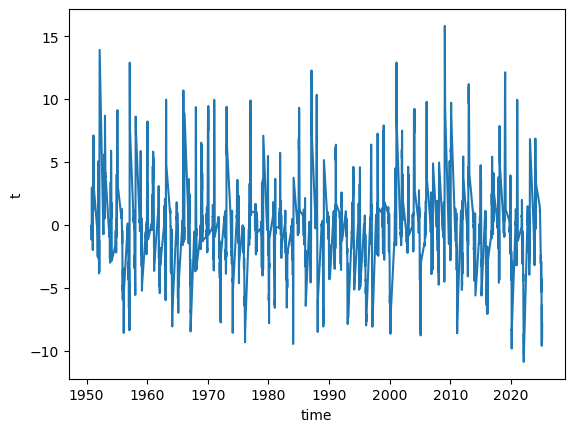

In [15]:
var_7dMean_regmean_detr_anom.plot()

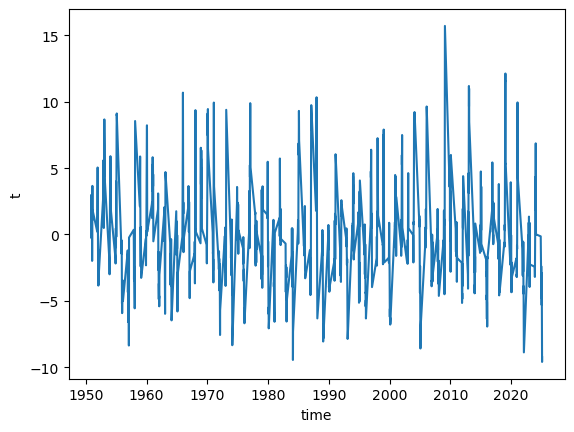

In [16]:
month = var_7dMean_regmean_detr_anom.time.dt.month
day = var_7dMean_regmean_detr_anom.time.dt.day
var_7dMean_regmean_detr_anom_week3 = var_7dMean_regmean_detr_anom.sel(time = ((month == 11) & (day >= 13)) | (month == 12) | (month == 1) | ((month == 2) & (day <= 4)))
var_7dMean_regmean_detr_anom_week4 = var_7dMean_regmean_detr_anom.sel(time = ((month == 11) & (day >= 6)) | (month == 12) | ((month == 1) & (day <= 28)))
var_7dMean_regmean_detr_anom_week5 = var_7dMean_regmean_detr_anom.sel(time = ((month == 10) & (day >= 30)) | (month == 11) | (month == 12) | ((month == 1) & (day <= 21)))
var_7dMean_regmean_detr_anom_week3.plot()

In [17]:
df_var_week3 = var_7dMean_regmean_detr_anom_week3.to_dataframe(name='st100_index')
df_var_week3 = df_var_week3.drop(['month_day'], axis=1)
df_var_week3

,st100_index
time,
1950-11-13,2.953999
1950-11-14,2.979962
1950-11-15,2.865862
1950-11-16,2.598367
1950-11-17,2.205734
...,...
2025-01-31,-8.919662
2025-02-01,-9.469343
2025-02-02,-9.603680


In [18]:
df_var_week4 = var_7dMean_regmean_detr_anom_week4.to_dataframe(name='st100_index')
df_var_week4 = df_var_week4.drop(['month_day'], axis=1)
df_var_week4

,st100_index
time,
1950-11-06,0.648158
1950-11-07,0.886734
1950-11-08,1.152239
1950-11-09,1.548969
1950-11-10,2.038522
...,...
2025-01-24,-6.069150
2025-01-25,-6.105164
2025-01-26,-6.168487


In [19]:
df_var_week5 = var_7dMean_regmean_detr_anom_week5.to_dataframe(name='st100_index')
df_var_week5 = df_var_week5.drop(['month_day'], axis=1)
df_var_week5

,st100_index
time,
1950-10-30,-0.937258
1950-10-31,-0.752326
1950-11-01,-0.536068
1950-11-02,-0.272325
1950-11-03,-0.018205
...,...
2025-01-17,-4.356769
2025-01-18,-4.536125
2025-01-19,-4.830428


In [20]:
df_var_week3.to_csv('st100_index_week3.csv')

In [20]:
df_var_week4.to_csv('st100_index_week4.csv')
df_var_week5.to_csv('st100_index_week5.csv')

In [21]:
df_u10_v2 = pd.read_csv('u10_60N_v2_week3.csv')

In [23]:
df_u10 = pd.read_csv('../Part1_analysis/u10_60N_week3.csv')

In [24]:
print(np.corrcoef(df_u10['u10_60N'], df_u10_v2['u10_60N_v2'])[0,1])

0.9996768606950222


In [27]:
print(np.corrcoef(df_u10['u10_60N'], df_var_week3['st100_index'])[0,1])

-0.9116725168032247


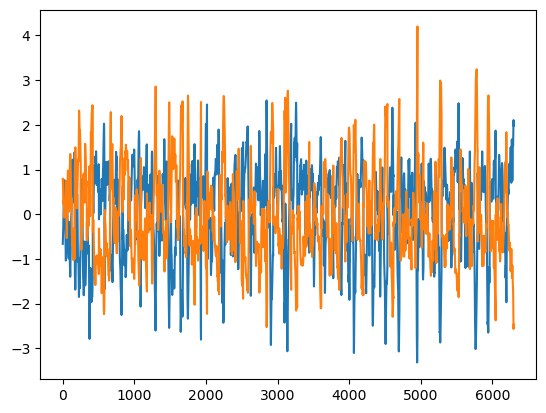

In [33]:
plt.plot(range(6300),df_u10['u10_60N']/df_u10['u10_60N'].std())
plt.plot(range(6300),df_var_week3['st100_index']/df_var_week3['st100_index'].std())